In [2]:
import sys
sys.path.insert(0, "..")

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from config import AUDIO_FEATURES
from data import load_data, clean_data

df = load_data()
df_clean = clean_data(df)

2026-10-29 09:22:04.403 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 09:22:04.406 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 09:22:04.407 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 09:22:04.408 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-10-29 09:22:05.537 WARNING streamlit.runtime.caching.cache_data_api: No runtime found, using MemoryCacheStorageManager
2026-10-29 09:22:05.625 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.


In [3]:
# 🎓 Projet Machine Learning n°2 — Spotify : décrypter la musique 🎧
# 1. **Structure** : dimensions, types, valeurs manquantes.
print("Dimensions :", df.shape)

df.info()

print(df.isnull().sum())

df.describe()

Dimensions : (32833, 23)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32833 entries, 0 to 32832
Data columns (total 23 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   track_id                  32833 non-null  object 
 1   track_name                32828 non-null  object 
 2   track_artist              32828 non-null  object 
 3   track_popularity          32833 non-null  int64  
 4   track_album_id            32833 non-null  object 
 5   track_album_name          32828 non-null  object 
 6   track_album_release_date  32833 non-null  object 
 7   playlist_name             32833 non-null  object 
 8   playlist_id               32833 non-null  object 
 9   playlist_genre            32833 non-null  object 
 10  playlist_subgenre         32833 non-null  object 
 11  danceability              32833 non-null  float64
 12  energy                    32833 non-null  float64
 13  key                       32833 non-

,track_popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,duration_ms
count,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000,32833.000000
mean,42.477081,0.654850,0.698619,5.374471,-6.719499,0.565711,0.107068,0.175334,0.084747,0.190176,0.510561,120.881132,225799.811622
std,24.984074,0.145085,0.180910,3.611657,2.988436,0.495671,0.101314,0.219633,0.224230,0.154317,0.233146,26.903624,59834.006182
min,0.000000,0.000000,0.000175,0.000000,-46.448000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,4000.000000
25%,24.000000,0.563000,0.581000,2.000000,-8.171000,0.000000,0.041000,0.015100,0.000000,0.092700,0.331000,99.960000,187819.000000
50%,45.000000,0.672000,0.721000,6.000000,-6.166000,1.000000,0.062500,0.080400,0.000016,0.127000,0.512000,121.984000,216000.000000
75%,62.000000,0.761000,0.840000,9.000000,-4.645000,1.000000,0.132000,0.255000,0.004830,0.248000,0.693000,133.918000,253585.000000
max,100.000000,0.983000,1.000000,11.000000,1.275000,1.000000,0.918000,0.994000,0.994000,0.996000,0.991000,239.440000,517810.000000


In [4]:
# 2. **Doublons** :
print("Nombre de lignes :", len(df))
print("Morceaux uniques :", df["track_id"].nunique())

nb_genres = df.groupby("track_id")["playlist_genre"].nunique()

print("Morceaux avec plusieurs genres :", (nb_genres > 1).sum())

Nombre de lignes : 32833
Morceaux uniques : 28356
Morceaux avec plusieurs genres : 1687


In [5]:
# 3. **Changements de types et nouvelles variables** :

print(df_clean[["release_year", "duration_min", "playlist_genre"]].head())

print(df_clean.dtypes)

print("Doublons restants :", df_clean["track_id"].duplicated().sum())

   release_year  duration_min playlist_genre
0          2019      3.245900            pop
1          2019      2.710000            pop
2          2019      2.943600            pop
3          2019      2.818217            pop
4          2019      3.150867            pop
track_id                      object
track_name                    object
track_artist                  object
track_popularity               int64
track_album_id                object
track_album_name              object
track_album_release_date      object
playlist_name                 object
playlist_id                   object
playlist_genre              category
playlist_subgenre             object
danceability                 float64
energy                       float64
key                            int64
loudness                     float64
mode                           int64
speechiness                  float64
acousticness                 float64
instrumentalness             float64
liveness                   

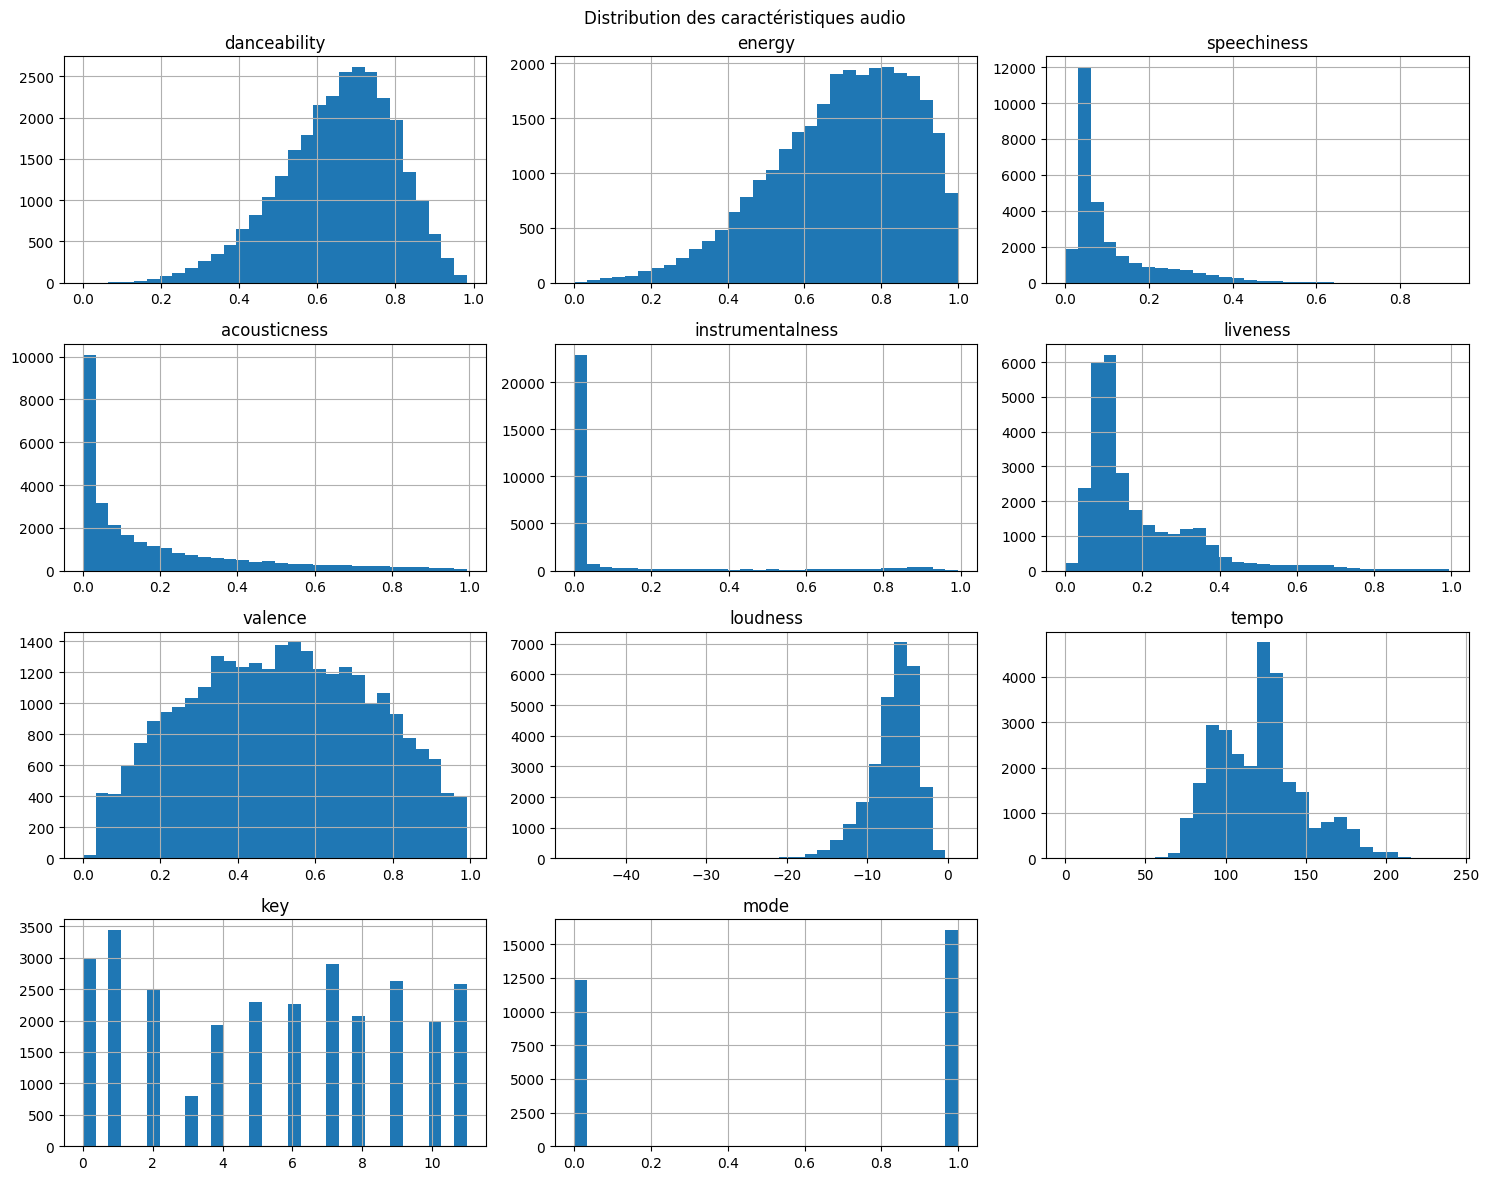

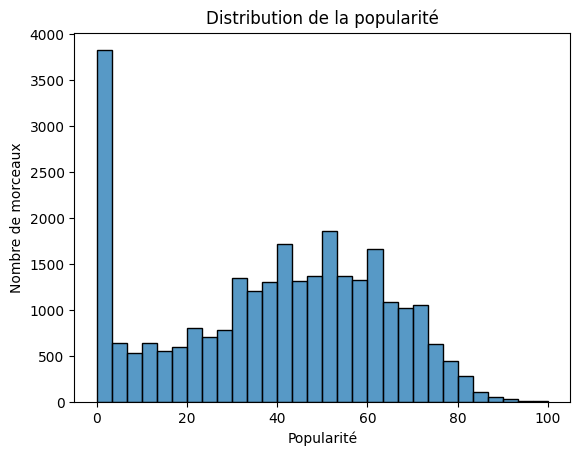

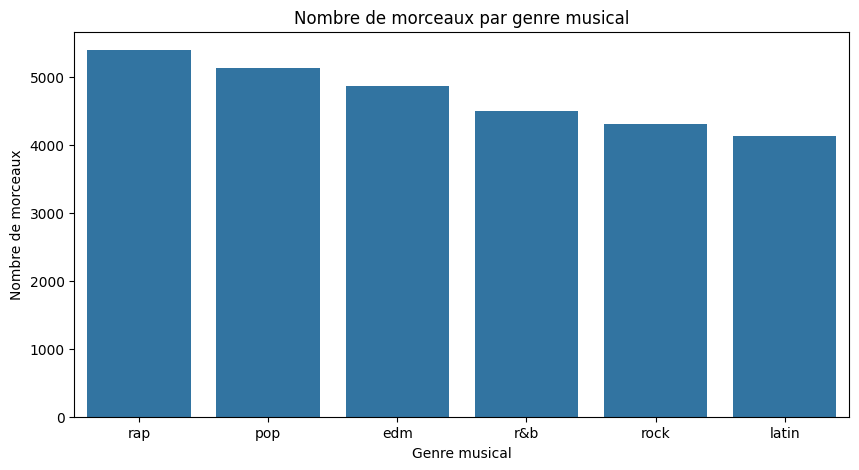

playlist_genre
rap      5401
pop      5132
edm      4877
r&b      4504
rock     4305
latin    4137
Name: count, dtype: int64


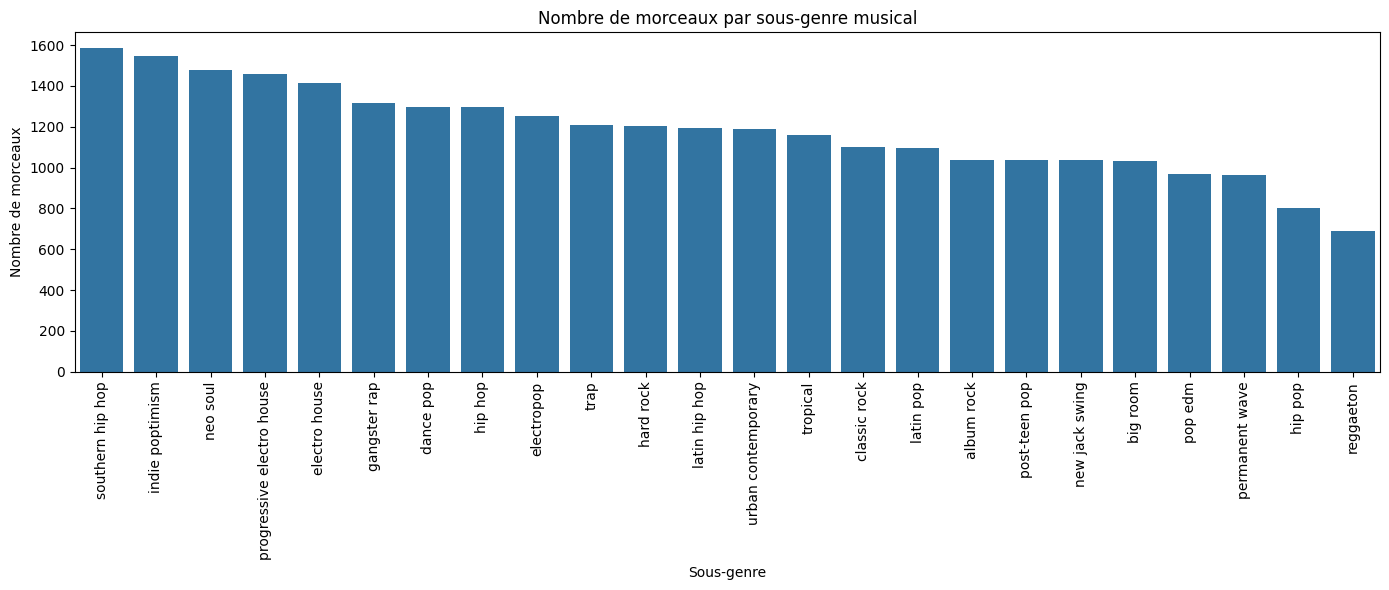

In [8]:
# 4. Analyse univariée : caractéristiques audio

df_clean[AUDIO_FEATURES].hist(
    figsize=(15, 12),
    bins=30
)

plt.suptitle("Distribution des caractéristiques audio")
plt.tight_layout()
plt.show()

sns.histplot(data=df_clean, x="track_popularity", bins=30)

plt.title("Distribution de la popularité")
plt.xlabel("Popularité")
plt.ylabel("Nombre de morceaux")
plt.show()


# 4.4 Nombre de morceaux par genre

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df_clean,
    x="playlist_genre",
    order=df_clean["playlist_genre"].value_counts().index
)

plt.title("Nombre de morceaux par genre musical")
plt.xlabel("Genre musical")
plt.ylabel("Nombre de morceaux")
plt.show()

# Afficher les valeurs exactes
print(df_clean["playlist_genre"].value_counts())

# 4.5 Nombre de morceaux par sous-genre

plt.figure(figsize=(14, 6))

sns.countplot(
    data=df_clean,
    x="playlist_subgenre",
    order=df_clean["playlist_subgenre"].value_counts().index
)

plt.title("Nombre de morceaux par sous-genre musical")
plt.xlabel("Sous-genre")
plt.ylabel("Nombre de morceaux")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

Caractéristiques audio :

Les morceaux Spotify présentent généralement une énergie (energy) et une capacité à danser (danceability) assez élevées. En revanche, les valeurs de speechiness, acousticness et instrumentalness sont souvent proches de zéro.

Le tempo (tempo) se situe principalement entre 90 et 140 BPM. La variable valence, qui représente le caractère positif d'une musique, est assez bien répartie entre 0 et 1.

Popularité :

La popularité des morceaux se concentre principalement entre 30 et 70. On observe également un nombre important de morceaux ayant une popularité égale à zéro.

Il serait intéressant de vérifier pourquoi autant de morceaux ont cette valeur. Le graphique seul ne permet pas de savoir s'il s'agit réellement de morceaux peu populaires ou de valeurs particulières du dataset.

===== 1. STATISTIQUES GÉNÉRALES =====
Nombre total de morceaux : 28356
Morceaux avec popularité 0 : 2620
Morceaux avec popularité positive : 25736
Valeurs manquantes : 0
Pourcentage de morceaux à 0 : 9.24 %

===== 2. EXEMPLES DE MORCEAUX =====


,track_name,track_artist,release_year,playlist_genre,track_popularity
476,Siren,SUNMI,2018,pop,0
772,Lollipop (Candyman),Aqua,2009,pop,0
801,Around The World,Aqua,2009,pop,0
883,I'm Yours,Influencers Worship,2018,pop,0
934,Talk About It,Bancali,2018,pop,0
935,You Don't Know Me (feat. Duane Harden) - Radio...,Armand Van Helden,2012,pop,0
1047,TURN,TaeyoungBoy,2019,pop,0
1613,Heaven,The Neighbourhood,2018,pop,0
1614,Kings of the Mountain,Lonely The Brave,2014,pop,0
1630,Gossip,You Me At Six,2008,pop,0



===== 3. POPULARITÉ 0 PAR GENRE =====


,total,popularite_zero,pourcentage_zero
playlist_genre,,,
edm,4877,650,13.33
r&b,4504,488,10.83
rock,4305,385,8.94
latin,4137,348,8.41
rap,5401,436,8.07
pop,5132,313,6.10


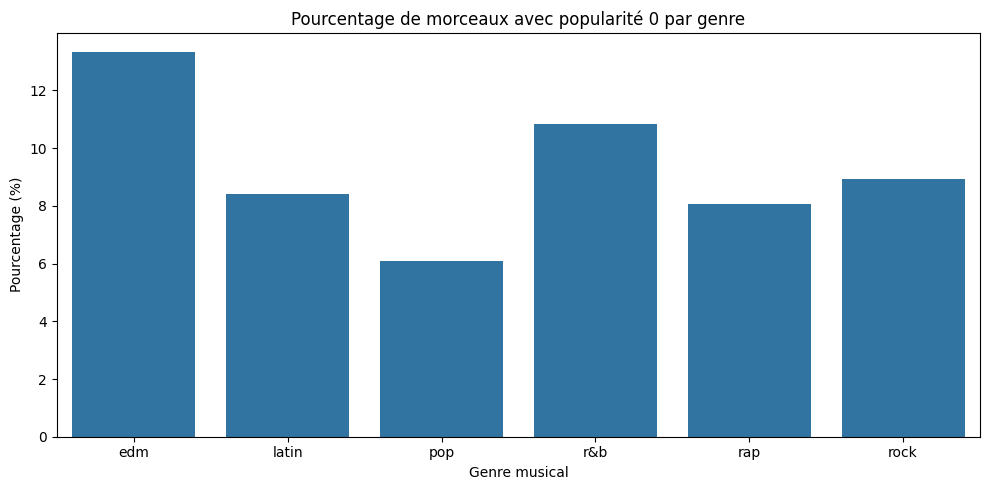


===== 4. POPULARITÉ 0 PAR SOUS-GENRE =====


,total,popularite_zero,pourcentage_zero
playlist_subgenre,,,
progressive electro house,1460,299,20.48
new jack swing,1036,201,19.40
gangster rap,1316,236,17.93
latin hip hop,1194,191,16.00
neo soul,1478,187,12.65
hard rock,1202,147,12.23
album rock,1039,125,12.03
big room,1034,120,11.61
electropop,1251,144,11.51



===== 5. POPULARITÉ 0 PAR ANNÉE =====


,total,popularite_zero,pourcentage_zero
release_year,,,
2001,290,40,13.79
2002,235,24,10.21
2003,324,56,17.28
2004,354,43,12.15
2005,465,113,24.30
2006,425,67,15.76
2007,444,71,15.99
2008,590,190,32.20
2009,450,110,24.44


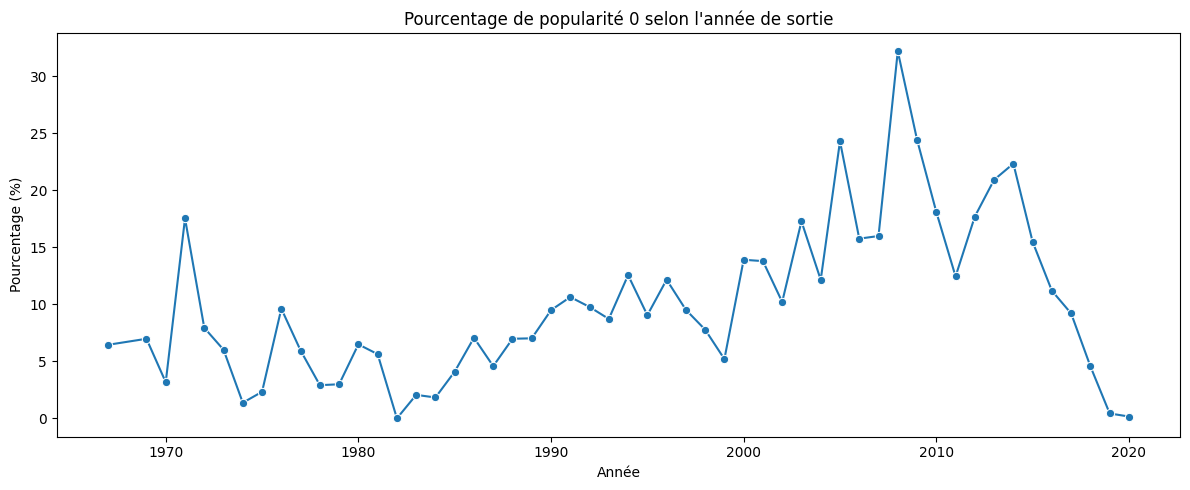


===== 6. ARTISTES AVEC LE PLUS DE MORCEAUX À 0 =====


,nombre_morceaux_zero
track_artist,
Ballin Entertainment,42
Miguel Rios,29
Javiera Mena,29
Rick Ross,21
CASIOPEA,20
Lynyrd Skynyrd,19
Guy,18
50 Cent,18
All Time Low,17



===== 7. ANALYSE DES DOUBLONS =====
Nombre de lignes brutes : 32833
Nombre de lignes nettoyées : 28356
Lignes supprimées : 4477
Morceaux avec popularité 0 ET popularité positive : 0
Aucun morceau avec un même track_id ne présente ces deux scores.

===== 8. COMPARAISON DES DEUX GROUPES =====


,nombre,annee_mediane,duree_moyenne,energie_moyenne,danceability_moyenne
groupe,,,,,
Popularité 0,2620,2012.0,4.10,0.74,0.64
Popularité positive,25736,2016.0,3.74,0.69,0.65



===== FIN DE L'ANALYSE =====


In [13]:
# =========================================================
# ANALYSE DES MORCEAUX AVEC UNE POPULARITÉ DE 0
# =========================================================

import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

# Séparer les morceaux avec et sans popularité
df_zero = df_clean[df_clean["track_popularity"] == 0]
df_autres = df_clean[df_clean["track_popularity"] > 0]

# =========================================================
# 1. STATISTIQUES GÉNÉRALES
# =========================================================

print("===== 1. STATISTIQUES GÉNÉRALES =====")

print("Nombre total de morceaux :", len(df_clean))
print("Morceaux avec popularité 0 :", len(df_zero))
print("Morceaux avec popularité positive :", len(df_autres))
print("Valeurs manquantes :", df_clean["track_popularity"].isna().sum())

pourcentage = len(df_zero) / len(df_clean) * 100
print("Pourcentage de morceaux à 0 :", round(pourcentage, 2), "%")

# =========================================================
# 2. EXEMPLES DE MORCEAUX CONCERNÉS
# =========================================================

print("\n===== 2. EXEMPLES DE MORCEAUX =====")

display(
    df_zero[
        ["track_name", "track_artist", "release_year",
         "playlist_genre", "track_popularity"]
    ].head(20)
)

# =========================================================
# 3. POPULARITÉ 0 PAR GENRE
# =========================================================

print("\n===== 3. POPULARITÉ 0 PAR GENRE =====")

genres = df_clean.groupby("playlist_genre", observed=True).agg(
    total=("track_popularity", "size"),
    popularite_zero=("track_popularity", lambda x: (x == 0).sum())
)

genres["pourcentage_zero"] = (
    genres["popularite_zero"] / genres["total"] * 100
).round(2)

genres = genres.sort_values("pourcentage_zero", ascending=False)

display(genres)

plt.figure(figsize=(10, 5))
sns.barplot(
    x=genres.index,
    y=genres["pourcentage_zero"]
)
plt.title("Pourcentage de morceaux avec popularité 0 par genre")
plt.xlabel("Genre musical")
plt.ylabel("Pourcentage (%)")
plt.tight_layout()
plt.show()

# =========================================================
# 4. SOUS-GENRES LES PLUS CONCERNÉS
# =========================================================

print("\n===== 4. POPULARITÉ 0 PAR SOUS-GENRE =====")

sous_genres = df_clean.groupby("playlist_subgenre").agg(
    total=("track_popularity", "size"),
    popularite_zero=("track_popularity", lambda x: (x == 0).sum())
)

sous_genres["pourcentage_zero"] = (
    sous_genres["popularite_zero"] / sous_genres["total"] * 100
).round(2)

display(
    sous_genres.sort_values("pourcentage_zero", ascending=False)
)

# =========================================================
# 5. POPULARITÉ 0 SELON L'ANNÉE DE SORTIE
# =========================================================

print("\n===== 5. POPULARITÉ 0 PAR ANNÉE =====")

annees = df_clean.groupby("release_year").agg(
    total=("track_popularity", "size"),
    popularite_zero=("track_popularity", lambda x: (x == 0).sum())
)

annees["pourcentage_zero"] = (
    annees["popularite_zero"] / annees["total"] * 100
).round(2)

display(annees.tail(20))

# Afficher uniquement les années avec au moins 30 morceaux
annees_graph = annees[annees["total"] >= 30]

plt.figure(figsize=(12, 5))
sns.lineplot(
    x=annees_graph.index,
    y=annees_graph["pourcentage_zero"],
    marker="o"
)
plt.title("Pourcentage de popularité 0 selon l'année de sortie")
plt.xlabel("Année")
plt.ylabel("Pourcentage (%)")
plt.tight_layout()
plt.show()

# =========================================================
# 6. ARTISTES LES PLUS CONCERNÉS
# =========================================================

print("\n===== 6. ARTISTES AVEC LE PLUS DE MORCEAUX À 0 =====")

artistes = df_zero["track_artist"].value_counts().head(15)

display(artistes.to_frame(name="nombre_morceaux_zero"))

# =========================================================
# 7. VÉRIFIER LES DOUBLONS DANS LES DONNÉES BRUTES
# =========================================================

print("\n===== 7. ANALYSE DES DOUBLONS =====")

print("Nombre de lignes brutes :", len(df))
print("Nombre de lignes nettoyées :", len(df_clean))
print("Lignes supprimées :", len(df) - len(df_clean))

# Chercher les morceaux ayant plusieurs scores de popularité
popularites = df.groupby("track_id")["track_popularity"].agg(
    ["min", "max"]
)

morceaux_differents = popularites[
    (popularites["min"] == 0) &
    (popularites["max"] > 0)
]

print(
    "Morceaux avec popularité 0 ET popularité positive :",
    len(morceaux_differents)
)

# Afficher quelques exemples si nécessaire
if len(morceaux_differents) > 0:
    exemples = df[
        df["track_id"].isin(morceaux_differents.index)
    ][
        ["track_id", "track_name", "track_artist",
         "track_popularity", "playlist_genre"]
    ]

    display(exemples.head(20))
else:
    print("Aucun morceau avec un même track_id ne présente ces deux scores.")

# =========================================================
# 8. COMPARER LES MORCEAUX À 0 ET LES AUTRES
# =========================================================

print("\n===== 8. COMPARAISON DES DEUX GROUPES =====")

comparaison = df_clean.copy()

comparaison["groupe"] = comparaison["track_popularity"].apply(
    lambda x: "Popularité 0" if x == 0 else "Popularité positive"
)

resume = comparaison.groupby("groupe").agg(
    nombre=("track_id", "size"),
    annee_mediane=("release_year", "median"),
    duree_moyenne=("duration_min", "mean"),
    energie_moyenne=("energy", "mean"),
    danceability_moyenne=("danceability", "mean")
)

display(resume.round(2))

print("\n===== FIN DE L'ANALYSE =====")

In [14]:
# Tous les morceaux de 50 Cent
fifty = df_clean[
    df_clean["track_artist"].str.lower() == "50 cent"
]

# Afficher leurs titres, albums et popularités
display(
    fifty[
        ["track_name", "track_album_name", "release_year",
         "track_popularity", "track_id"]
    ].sort_values("track_popularity")
)

# Rechercher d'autres versions des titres ayant une popularité de 0
titres_zero = fifty.loc[
    fifty["track_popularity"] == 0, "track_name"
].str.lower()

autres_versions = df_clean[
    (df_clean["track_artist"].str.lower() == "50 cent") &
    (df_clean["track_name"].str.lower().isin(titres_zero)) &
    (df_clean["track_popularity"] > 0)
]

print("Autres versions avec une popularité positive :")
display(
    autres_versions[
        ["track_name", "track_album_name", "track_popularity", "track_id"]
    ]
)

,track_name,track_album_name,release_year,track_popularity,track_id
8572,Crime Wave,Before I Self-Destruct,2009,0,0gDh8XfKdq9of5fxuyayq2
8733,Outta Control,The Massacre,2005,0,12k0ULCKBLP1CpscxX1Y4w
8787,I'll Whip Ya Head Boy,Window Shopper (International Version),2005,0,0GCh3K0s5opTzyU1mpdsSU
8620,Hustler's Ambition,Get Rich Or Die Tryin'- The Original Motion Pi...,2005,0,3gAvYSeYWyBMqGuLmrZs23
8605,Disco Inferno,Candy Shop (International Version),2005,0,12MDB5ARcX4wYVS1RnnRA1
8795,Smoke,Smoke,2014,0,3GaYENEtvaA1lpI9DEG0Cr
8577,Do You Think About Me,Before I Self-Destruct,2009,0,2Gnif8YLgt23hXwF9bJaOL
8796,Pilot,Pilot,2014,0,2caf8plDefqF1DXxAFWzgx
8566,Outlaw,Outlaw,2011,0,6m3blCKBMVimP5y8bTndD5
8544,Disco Inferno - Live from Sessions @ AOL,Just A Lil Bit (International Version),2005,0,0ctMHnma5rklnfurOKFXV0


Autres versions avec une popularité positive :


,track_name,track_album_name,track_popularity,track_id
7948,If I Can't,Get Rich Or Die Tryin',65,6mcu7D7QuABVwUGDwovOEh


Decouverte qu'il peut y avoir des doublons avec un track_id différent

In [15]:
# Comparer les deux versions de Just A Lil Bit

morceaux = df_clean[
    (df_clean["track_artist"] == "50 Cent") &
    (df_clean["track_name"] == "Just A Lil Bit")
]

colonnes = [
    "track_id", "track_name", "track_album_name",
    "track_popularity", "duration_ms",
    "danceability", "energy", "loudness",
    "speechiness", "acousticness", "instrumentalness",
    "liveness", "valence", "tempo", "key", "mode"
]

display(morceaux[colonnes].T)

,6051,8543,9155
track_id,68IM0wOuxlrbwk0zgmi9dk,2JxeAupAiJdB8I2cieG4rP,4nva9EpKntUTs6CRSGBCn9
track_name,Just A Lil Bit,Just A Lil Bit,Just A Lil Bit
track_album_name,The Massacre,The Massacre,The Massacre
track_popularity,3,2,75
duration_ms,237707,237707,237707
danceability,0.724,0.704,0.489
energy,0.692,0.683,0.692
loudness,-6.75,-6.617,-6.672
speechiness,0.324,0.328,0.41
acousticness,0.0397,0.0326,0.0322


10:00 : MOdification du fichier data.py pour supprimer les doublon en fonction du titre/artiste/album et garder celui avec la meilleur pop